<a href="https://colab.research.google.com/github/antonioboboc/covd19-ct-scan-segmentation/blob/main/notebooks/01_explorare_date.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

url = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "maedemaftouni/covid19-ct-scan-lesion-segmentation-dataset"
)

arhiva = Path("/content/ct_lesiuni.zip")
folder_date = Path("/content/ct_lesiuni")

if not arhiva.exists():
    print("Descarc setul de date...")
    fisier_temporar = arhiva.with_suffix(".part")
    urlretrieve(url, fisier_temporar)
    fisier_temporar.replace(arhiva)

print("Extrag fișierele...")
with ZipFile(arhiva) as zip_date:
    zip_date.extractall(folder_date)

print("Datele sunt gata.")
print("Conținut:", sorted(fisier.name for fisier in folder_date.iterdir()))

Descarc setul de date...
Extrag fișierele...
Datele sunt gata.
Conținut: ['frames', 'masks']


In [2]:
imagini = {fisier.stem: fisier for fisier in (folder_date / "frames").glob("*.png")}
masti = {fisier.stem: fisier for fisier in (folder_date / "masks").glob("*.png")}

nume_comune = sorted(imagini.keys() & masti.keys())
fara_masca = sorted(imagini.keys() - masti.keys())
fara_imagine = sorted(masti.keys() - imagini.keys())

perechi = [(imagini[nume], masti[nume]) for nume in nume_comune]

print(f"Imagini CT: {len(imagini)}")
print(f"Măști: {len(masti)}")
print(f"Perechi găsite: {len(perechi)}")
print(f"Imagini fără mască: {len(fara_masca)}")
print(f"Măști fără imagine: {len(fara_imagine)}")

if perechi:
    imagine, masca = perechi[0]
    print(f"Exemplu de pereche: {imagine.name} ↔ {masca.name}")

if fara_masca or fara_imagine:
    print("Exemple de imagini fără mască:", fara_masca[:3])
    print("Exemple de măști fără imagine:", fara_imagine[:3])


Imagini CT: 2729
Măști: 2729
Perechi găsite: 2729
Imagini fără mască: 0
Măști fără imagine: 0
Exemplu de pereche: Jun_coronacases_case10_100.png ↔ Jun_coronacases_case10_100.png


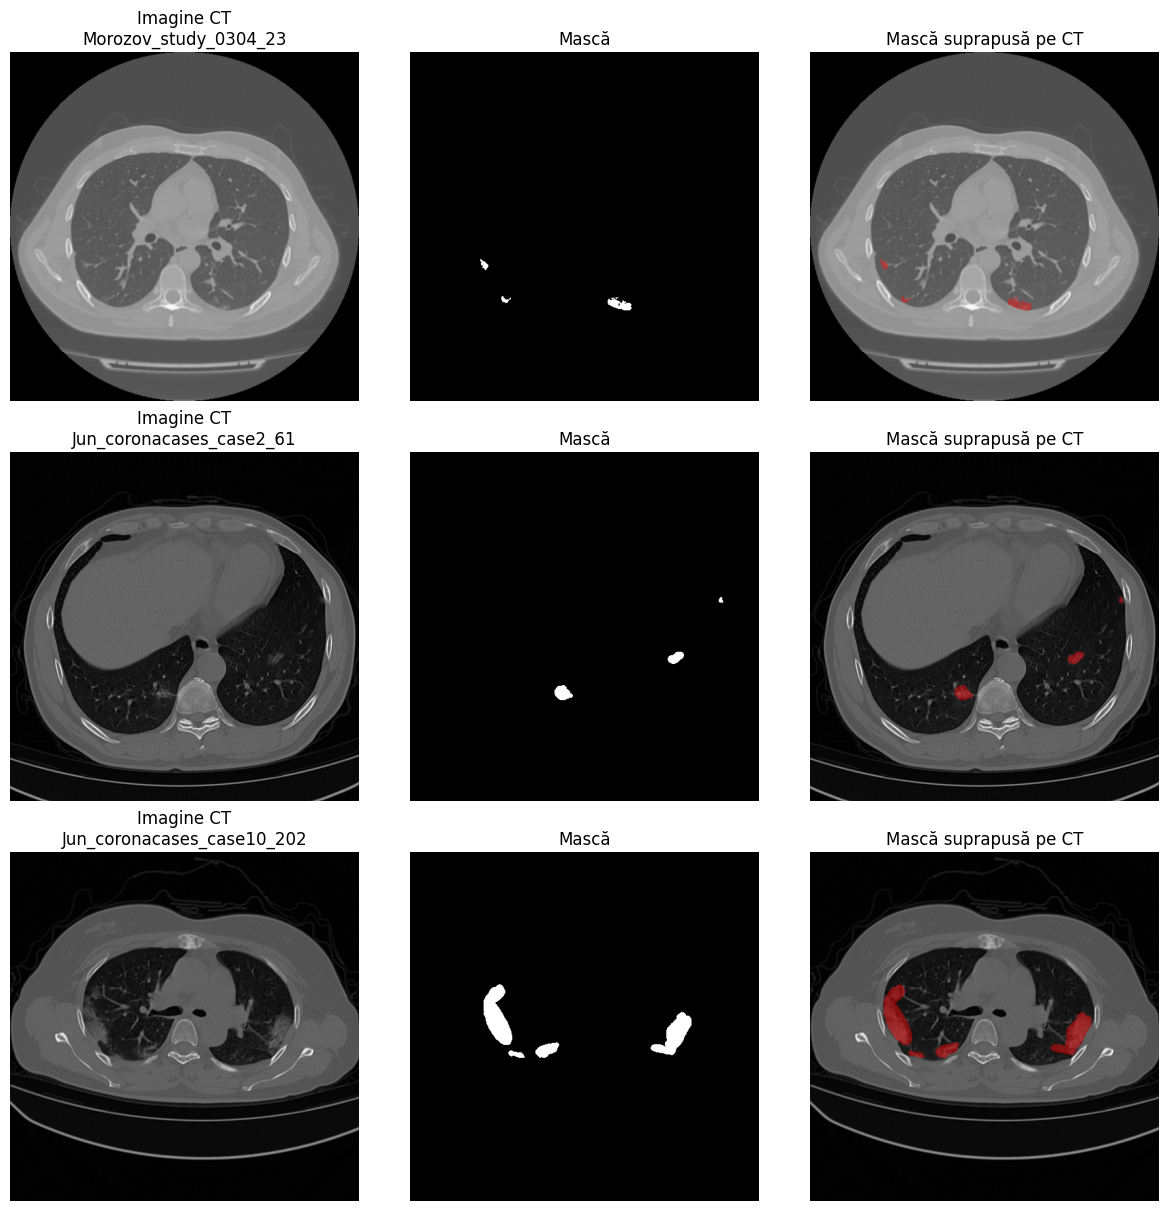

In [4]:
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

exemple = random.Random(42).sample(perechi, 3)
fig, axe = plt.subplots(3, 3, figsize=(12, 12), layout="constrained")

for rand, (cale_ct, cale_masca) in enumerate(exemple):
    with Image.open(cale_ct) as fisier_ct:
        ct = np.array(fisier_ct.convert("L"))

    with Image.open(cale_masca) as fisier_masca:
        masca = np.array(fisier_masca.convert("L"))

    if ct.shape != masca.shape:
        raise ValueError(
            f"Dimensiuni diferite pentru {cale_ct.name}: "
            f"CT {ct.shape}, mască {masca.shape}"
        )

    zona_marcata = masca > 0
    suprapunere = np.zeros((*masca.shape, 4))
    suprapunere[..., 0] = 1
    suprapunere[..., 3] = 0.45 * zona_marcata

    axe[rand, 0].imshow(ct, cmap="gray")
    axe[rand, 0].set_title(f"Imagine CT\n{cale_ct.stem}")

    axe[rand, 1].imshow(zona_marcata, cmap="gray", vmin=0, vmax=1)
    axe[rand, 1].set_title("Mască")

    axe[rand, 2].imshow(ct, cmap="gray")
    axe[rand, 2].imshow(suprapunere)
    axe[rand, 2].set_title("Mască suprapusă pe CT")

    for axa in axe[rand]:
        axa.axis("off")

plt.show()


In [5]:
from collections import Counter

total_pixeli = 0
pixeli_leziune = 0
masti_goale = 0
valori_masti = Counter()
dimensiuni_diferite = []

for cale_ct, cale_masca in perechi:
    with Image.open(cale_ct) as ct, Image.open(cale_masca) as masca:
        if ct.size != masca.size:
            dimensiuni_diferite.append(cale_ct.name)

        histograma = masca.convert("L").histogram()

    nr_pixeli = sum(histograma)
    nr_leziune = nr_pixeli - histograma[0]

    total_pixeli += nr_pixeli
    pixeli_leziune += nr_leziune
    masti_goale += nr_leziune == 0

    valori_masti.update({
        valoare: frecventa
        for valoare, frecventa in enumerate(histograma)
        if frecventa > 0
    })

pixeli_fundal = total_pixeli - pixeli_leziune

print(f"Perechi cu dimensiuni diferite: {len(dimensiuni_diferite)}")
print(f"Măști goale: {masti_goale} din {len(perechi)}")
print(f"Valori distincte în măștile grayscale: {sorted(valori_masti)}")
print(f"Pixeli de fundal: {pixeli_fundal:,} ({pixeli_fundal / total_pixeli:.2%})")
print(f"Pixeli marcați ca leziune: {pixeli_leziune:,} ({pixeli_leziune / total_pixeli:.2%})")

if dimensiuni_diferite:
    print("Exemple de perechi cu dimensiuni diferite:", dimensiuni_diferite[:5])

Perechi cu dimensiuni diferite: 0
Măști goale: 1 din 2729
Valori distincte în măștile grayscale: [0, 12, 17, 21, 255]
Pixeli de fundal: 704,377,537 (98.46%)
Pixeli marcați ca leziune: 11,013,439 (1.54%)


In [6]:
print("Valoare | Număr de pixeli")
for valoare, frecventa in sorted(valori_masti.items()):
    print(f"{valoare:>7} | {frecventa:,}")

pixeli_intermediari = sum(
    frecventa
    for valoare, frecventa in valori_masti.items()
    if 0 < valoare < 255
)

print(f"\nPixeli cu valori intermediare: {pixeli_intermediari:,}")
print(f"Pondere între pixelii nenuli: {pixeli_intermediari / pixeli_leziune:.4%}")
print(f"Procent de leziune dacă păstrăm doar 255: {valori_masti[255] / total_pixeli:.4%}")


Valoare | Număr de pixeli
      0 | 704,377,537
     12 | 60,640
     17 | 106,030
     21 | 59,832
    255 | 10,786,937

Pixeli cu valori intermediare: 226,502
Pondere între pixelii nenuli: 2.0566%
Procent de leziune dacă păstrăm doar 255: 1.5078%


In [7]:
masti_cu_valori_intermediare = []
masti_doar_cu_valori_intermediare = []

for _, cale_masca in perechi:
    with Image.open(cale_masca) as masca:
        histograma = masca.convert("L").histogram()

    are_valori_intermediare = any(histograma[1:255])
    are_255 = histograma[255] > 0

    if are_valori_intermediare:
        masti_cu_valori_intermediare.append(cale_masca.name)

        if not are_255:
            masti_doar_cu_valori_intermediare.append(cale_masca.name)

print("Măști cu valori intermediare:", len(masti_cu_valori_intermediare))
print("Măști care ar deveni goale dacă păstrăm doar 255:",
      len(masti_doar_cu_valori_intermediare))
print("Exemple:", masti_doar_cu_valori_intermediare[:5])


Măști cu valori intermediare: 99
Măști care ar deveni goale dacă păstrăm doar 255: 0
Exemple: []


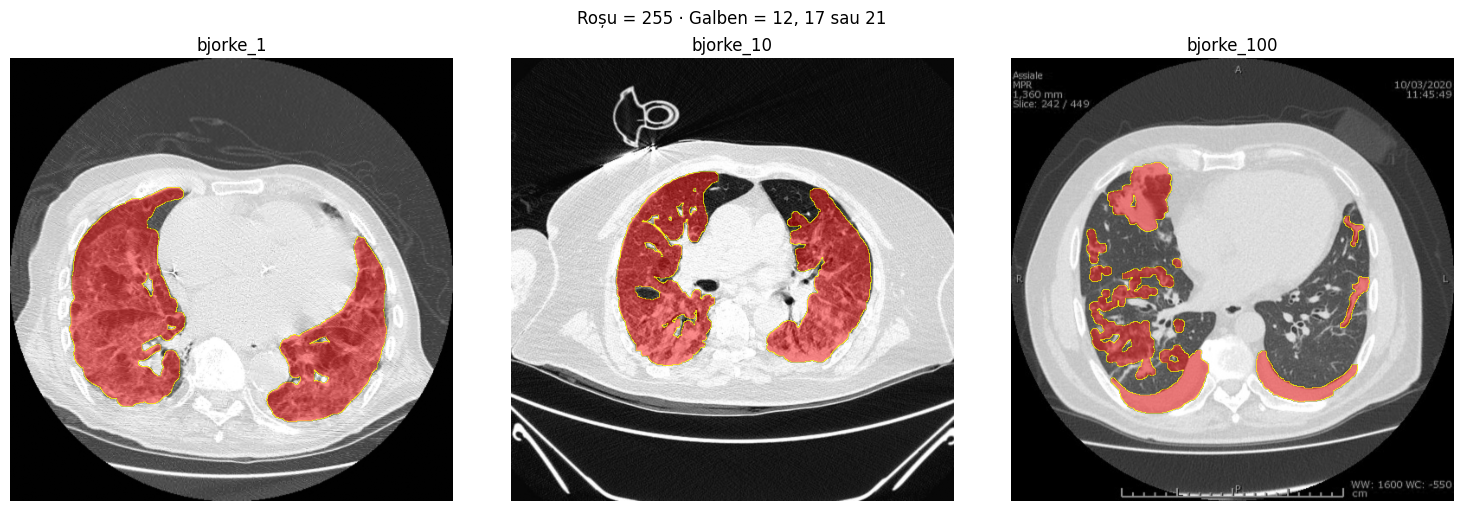

In [8]:
fig, axe = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")

for axa, nume in zip(axe, masti_cu_valori_intermediare[:3]):
    identificator = Path(nume).stem

    with Image.open(imagini[identificator]) as fisier_ct:
        ct = np.array(fisier_ct.convert("L"))

    with Image.open(masti[identificator]) as fisier_masca:
        masca = np.array(fisier_masca.convert("L"))

    suprapunere = np.zeros((*masca.shape, 4))
    suprapunere[masca == 255] = [1, 0, 0, 0.45]
    suprapunere[(masca > 0) & (masca < 255)] = [1, 1, 0, 0.85]

    axa.imshow(ct, cmap="gray")
    axa.imshow(suprapunere)
    axa.set_title(identificator)
    axa.axis("off")

fig.suptitle("Roșu = 255 · Galben = 12, 17 sau 21")
plt.show()


In [9]:
prefixe = Counter()

for cale_ct, _ in perechi:
    prefix, separator, sufix = cale_ct.stem.rpartition("_")

    if separator and sufix.isdigit():
        prefixe[prefix] += 1
    else:
        prefixe["(alt format de nume)"] += 1

print(f"Prefixe distincte: {len(prefixe)}")
print("Cele mai frecvente prefixe:")
for prefix, numar in prefixe.most_common(20):
    print(f"{prefix}: {numar} imagini")


Prefixe distincte: 71
Cele mai frecvente prefixe:
Jun_coronacases_case8: 216 imagini
Jun_coronacases_case10: 191 imagini
Jun_coronacases_case1: 161 imagini
Jun_radiopaedia_10_85902_3_case12: 148 imagini
Jun_coronacases_case2: 143 imagini
Jun_coronacases_case3: 137 imagini
Jun_coronacases_case5: 116 imagini
Jun_coronacases_case4: 113 imagini
Jun_coronacases_case9: 111 imagini
Jun_radiopaedia_14_85914_0_case13: 103 imagini
bjorke: 100 imagini
Jun_coronacases_case7: 93 imagini
Jun_radiopaedia_40_86625_0_case18: 72 imagini
Jun_coronacases_case6: 70 imagini
Jun_radiopaedia_27_86410_0_case14: 44 imagini
Jun_radiopaedia_7_85703_0_case20: 41 imagini
Morozov_study_0297: 36 imagini
Jun_radiopaedia_36_86526_0_case17: 34 imagini
Jun_radiopaedia_4_85506_1_case19: 26 imagini
Morozov_study_0256: 25 imagini


In [10]:
import re

tipar_caz = re.compile(
    r"Jun_(?:coronacases|radiopaedia_.+)_case\d+|Morozov_study_\d+"
)

neclare = {
    prefix: numar
    for prefix, numar in prefixe.items()
    if not tipar_caz.fullmatch(prefix)
}

print(f"Prefixe rămase de verificat: {len(neclare)}")
for prefix, numar in sorted(neclare.items()):
    print(f"{prefix}: {numar} imagini")


Prefixe rămase de verificat: 1
bjorke: 100 imagini


In [11]:
from sklearn.model_selection import GroupShuffleSplit

# Scoatem numărul secțiunii de la finalul numelui.
grupuri = np.array([
    cale_ct.stem.rsplit("_", 1)[0]
    for cale_ct, _ in perechi
])
indici = np.arange(len(perechi))

# Păstrăm aproximativ 30% dintre grupuri pentru validare și test.
prima_impartire = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
antrenare, ramase = next(prima_impartire.split(indici, groups=grupuri))

# Împărțim grupurile rămase în două părți.
a_doua_impartire = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
validare_relativ, test_relativ = next(
    a_doua_impartire.split(ramase, groups=grupuri[ramase])
)
validare = ramase[validare_relativ]
test = ramase[test_relativ]

partitii = {
    "Antrenare": antrenare,
    "Validare": validare,
    "Test": test,
}

grupuri_pe_partitie = [set(grupuri[subset]) for subset in partitii.values()]
assert sum(map(len, grupuri_pe_partitie)) == len(set(grupuri))
assert sum(map(len, partitii.values())) == len(perechi)

for nume, subset in partitii.items():
    print(
        f"{nume}: {len(subset)} imagini "
        f"({len(subset) / len(perechi):.1%}), "
        f"{len(set(grupuri[subset]))} grupuri"
    )

print("Verificare: fiecare grup apare într-o singură partiție.")

Antrenare: 1837 imagini (67.3%), 49 grupuri
Validare: 301 imagini (11.0%), 11 grupuri
Test: 591 imagini (21.7%), 11 grupuri
Verificare: fiecare grup apare într-o singură partiție.


In [12]:
import csv
from google.colab import files

cale_csv = Path("/content/partitii_ct.csv")

with cale_csv.open("w", newline="", encoding="utf-8") as fisier:
    tabel = csv.writer(fisier)
    tabel.writerow(["imagine", "masca", "grup", "partitie"])

    for partitie, subset in partitii.items():
        for index in subset:
            cale_ct, cale_masca = perechi[index]
            tabel.writerow([
                cale_ct.relative_to(folder_date).as_posix(),
                cale_masca.relative_to(folder_date).as_posix(),
                grupuri[index],
                partitie,
            ])

print(f"Excel/CSV: {cale_csv.name} — {len(perechi)} perechi salvate.")
files.download(str(cale_csv))


Excel/CSV: partitii_ct.csv — 2729 perechi salvate.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>